# PHO Infectious Disease Surveillance Analysis
## 04 | Dashboard Preparation & Validation

**Goal:** Prepare reproducible, validated datasets and a compact interactive preview for the **Streamlit** and **Tableau Public** dashboards.

**Inputs:** the three tidy CSV files exported by Notebook 02, under `outputs/processed/`.  
**Outputs:** dashboard-ready CSV files in `outputs/dashboard/`.  
**Scope:** public-health surveillance **aggregates**, not patient-level data or individual risk predictions.

> **Reporting guardrails:** Never sum `Ontario` with individual PHUs, never combine `Canada` with Ontario, and never treat missing denominators as zero. Preserve outcome and demographic reporting grains. The 2025 reporting status must be verified before presenting it as final.

### 01 | Dependencies, Configuration & Project Paths

Run this notebook from the PHO project root or its `notebooks` directory. No manual changes to absolute Windows paths are required.

In [3]:
# ============================================================
# 01 | Dependencies, Configuration & Project Paths
# ============================================================
from pathlib import Path
import numpy as np
import pandas as pd
import plotly.express as px
from IPython.display import display

pd.set_option("display.max_columns", 16)
REFERENCE_YEAR = 2024
PREVIEW_DISEASE = "Lyme Disease"
EXPORT_TABLES = True

# Locate the same processed data used by Notebook 03.
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "outputs" / "processed" / "pho_overall_tidy.csv").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot find outputs/processed/pho_overall_tidy.csv; open from the PHO project folder.")
INPUT_DIR = PROJECT_ROOT / "outputs" / "processed"
DASHBOARD_DIR = PROJECT_ROOT / "outputs" / "dashboard"
print("Project:", PROJECT_ROOT)
print("Dashboard exports:", DASHBOARD_DIR)

Project: c:\Users\Honar\Downloads\PHO Project
Dashboard exports: c:\Users\Honar\Downloads\PHO Project\outputs\dashboard


### 02 | Load Processed Sources & Validate Their Schemas

Each dataset has a distinct **grain**, so joins across all three tables would otherwise multiply observations.

In [4]:
# ============================================================
# 02 | Load Processed Data & Validate Required Fields
# ============================================================
sources = {
    "overall": ("pho_overall_tidy.csv", ["Public health unit", "Disease", "Year", "Cases", "Population", "Rate per 100,000"]),
    "age_sex": ("pho_age_sex_tidy.csv", ["Public health unit", "Disease", "Year", "Sex", "Age group", "Number of cases", "Population"]),
    "outcomes": ("pho_outcomes_tidy.csv", ["Public health unit", "Disease", "Year", "Outcome", "Cases with outcome", "Total cases", "Percent of cases with outcome"]),
}
frames = {}
for name, (filename, columns) in sources.items():
    path = INPUT_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(f"Missing processed dataset: {path}")
    df = pd.read_csv(path)
    missing = sorted(set(columns) - set(df.columns))
    if missing:
        raise ValueError(f"{filename}: missing columns {missing}")
    df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
    if df["Year"].isna().any():
        raise ValueError(f"{filename}: invalid Year values")
    df["Year"] = df["Year"].astype(int)
    frames[name] = df

overall, age_sex, outcomes = (frames[k] for k in ("overall", "age_sex", "outcomes"))
for df, cols in [(overall, ["Cases", "Population", "Rate per 100,000"]),
                 (age_sex, ["Number of cases", "Population"]),
                 (outcomes, ["Cases with outcome", "Total cases", "Percent of cases with outcome"])]:
    for col in cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

display(pd.DataFrame([{"Dataset": name, "Rows": len(df), "Columns": df.shape[1]}
                      for name, df in frames.items()]))

,Dataset,Rows,Columns
0,overall,20034,8
1,age_sex,213741,8
2,outcomes,648,7


### 03 | Validate Unique Keys & Preserve Reporting Grains

Stop rather than silently aggregating a duplicate key. Different age strata and outcome types must remain separate.

In [5]:
# ============================================================
# 03 | Grain & Integrity Checks
# ============================================================
keys = {
    "overall": ["Public health unit", "Disease", "Year"],
    "age_sex": ["Public health unit", "Disease", "Year", "Sex", "Age group"],
    "outcomes": ["Public health unit", "Disease", "Year", "Outcome"],
}
for name, key in keys.items():
    n = frames[name].duplicated(key).sum()
    print(f"{name}: {n:,} duplicated reporting keys")
    if n:
        raise ValueError(f"{name} contains duplicate reporting keys; review Notebook 01 first.")

if (overall["Cases"].dropna() < 0).any() or (age_sex["Number of cases"].dropna() < 0).any():
    raise ValueError("Negative case counts detected.")
if ((overall["Population"].dropna() < 0).any() or
        (age_sex["Population"].dropna() < 0).any()):
    raise ValueError("Negative population denominator detected.")

print("Valid years:", overall["Year"].min(), "–", overall["Year"].max())
print("Reference year available:", REFERENCE_YEAR in overall["Year"].values)

overall: 0 duplicated reporting keys
age_sex: 0 duplicated reporting keys
outcomes: 0 duplicated reporting keys
Valid years: 2016 – 2025
Reference year available: True


### 04 | Disease Trends: Ontario-Only Table

Export raw annual counts and **PHO-reported** rates, not recomputed or averaged rates. Missing rates remain missing.

In [6]:
# ============================================================
# 04 | Ontario Disease Trends
# ============================================================
ontario_trends = (
    overall.loc[overall["Public health unit"].eq("Ontario"),
                ["Disease", "Year", "Cases", "Population", "Rate per 100,000"]]
    .sort_values(["Disease", "Year"]).copy()
)
ontario_trends["Rate_available"] = (
    ontario_trends["Population"].gt(0) & ontario_trends["Rate per 100,000"].notna()
)
if ontario_trends.empty:
    raise ValueError("No Ontario records in the overall export.")
print("Ontario trend rows:", len(ontario_trends))
display(ontario_trends.head(5))

Ontario trend rows: 630


,Disease,Year,Cases,Population,"Rate per 100,000",Rate_available
0,Acquired immunodeficiency syndrome (AIDS),2016,66,13876500,0.48,True
1925,Acquired immunodeficiency syndrome (AIDS),2017,64,14078499,0.45,True
3850,Acquired immunodeficiency syndrome (AIDS),2018,73,14326746,0.51,True
5835,Acquired immunodeficiency syndrome (AIDS),2019,64,14573565,0.44,True
7820,Acquired immunodeficiency syndrome (AIDS),2020,66,14761811,0.45,True


### 05 | PHU Comparison Table: Keep Geography Separate

Use disease-specific rate comparisons, **never** sum rates or add PHU cases to Ontario totals. PHU boundaries and names can change over time; this notebook does not harmonize historical geography.

In [7]:
# ============================================================
# 05 | Local PHU Disease Rates
# ============================================================
phu_rates = overall.loc[
    ~overall["Public health unit"].isin(["Ontario", "Canada"]),
    ["Public health unit", "Disease", "Year", "Cases", "Population", "Rate per 100,000"]
].copy()
phu_rates["Rate_available"] = (
    phu_rates["Population"].gt(0) & phu_rates["Rate per 100,000"].notna()
)
phu_rates = phu_rates.sort_values(["Disease", "Public health unit", "Year"])
print("PHU rows:", len(phu_rates))
print("PHU areas:", phu_rates["Public health unit"].nunique())

PHU rows: 18734
PHU areas: 29


### 06 | Age × Sex Table: Preserve Disease-Specific Strata

Only the Ontario aggregate is prepared for the default dashboard demographics. Do **not** sum across age bins from different diseases or present case counts as age-/sex-specific risk. The original sex categories, including missing values, are preserved.

In [8]:
# ============================================================
# 06 | Ontario Age & Sex Detail
# ============================================================
demographics = age_sex.loc[
    age_sex["Public health unit"].eq("Ontario"),
    ["Disease", "Year", "Sex", "Age group", "Number of cases", "Population"]
].copy()
# Keep missing Sex values; do not turn them into Female or Male.
demographics = demographics.sort_values(["Disease", "Year", "Age group", "Sex"], na_position="last")
print("Age/sex rows:", len(demographics))
print("Unspecified sex records:", demographics["Sex"].isna().sum())

Age/sex rows: 7860
Unspecified sex records: 283


### 07 | Reported Outcome Percentages: Ontario Only

The outcome file has limited disease coverage. Do not impute missing years, outcomes, or disease combinations as zero. Report the supplied PHO percentage rather than incorrectly averaging percentages across rows.

In [9]:
# ============================================================
# 07 | Ontario Reported Outcomes
# ============================================================
reported_outcomes = outcomes.loc[
    outcomes["Public health unit"].eq("Ontario"),
    ["Disease", "Year", "Outcome", "Cases with outcome", "Total cases", "Percent of cases with outcome"]
].copy().sort_values(["Disease", "Outcome", "Year"])
print("Outcome rows:", len(reported_outcomes))
print("Diseases with outcome data:", reported_outcomes["Disease"].nunique())

Outcome rows: 648
Diseases with outcome data: 38


### 08 | Executive Summary: Case Counts for a Selected Year

Rank **diseases individually** within Ontario. Do not sum all diseases into a province-wide total, since reporting definitions and disease categories can overlap.

In [10]:
# ============================================================
# 08 | Top Diseases for Executive Cards
# ============================================================
top_diseases = (
    ontario_trends.loc[ontario_trends["Year"].eq(REFERENCE_YEAR),
                       ["Disease", "Year", "Cases"]]
    .dropna(subset=["Cases"])
    .sort_values("Cases", ascending=False)
    .head(15).reset_index(drop=True)
)
if top_diseases.empty:
    raise ValueError(f"No Ontario cases for {REFERENCE_YEAR}; choose another REFERENCE_YEAR.")
display(top_diseases.head(10))

,Disease,Year,Cases
0,Chlamydial Infections,2024,42824
1,Gonorrhoea (All Types),2024,13607
2,Hepatitis C,2024,3236
3,"Syphilis, Infectious",2024,2929
4,Salmonellosis,2024,2616
5,Campylobacter Enteritis,2024,2527
6,Lyme Disease,2024,2402
7,"Hepatitis B, chronic",2024,2103
8,"Streptococcus pneumoniae, Invasive",2024,1825
9,"Group A Streptococcal Disease, Invasive",2024,1793


### 09 | Visual QA: Disease Trend and PHU Rate Comparison

These are **preview charts**, not the final Streamlit app. The app will load the saved tables and expose interactive year/disease/PHU filters.

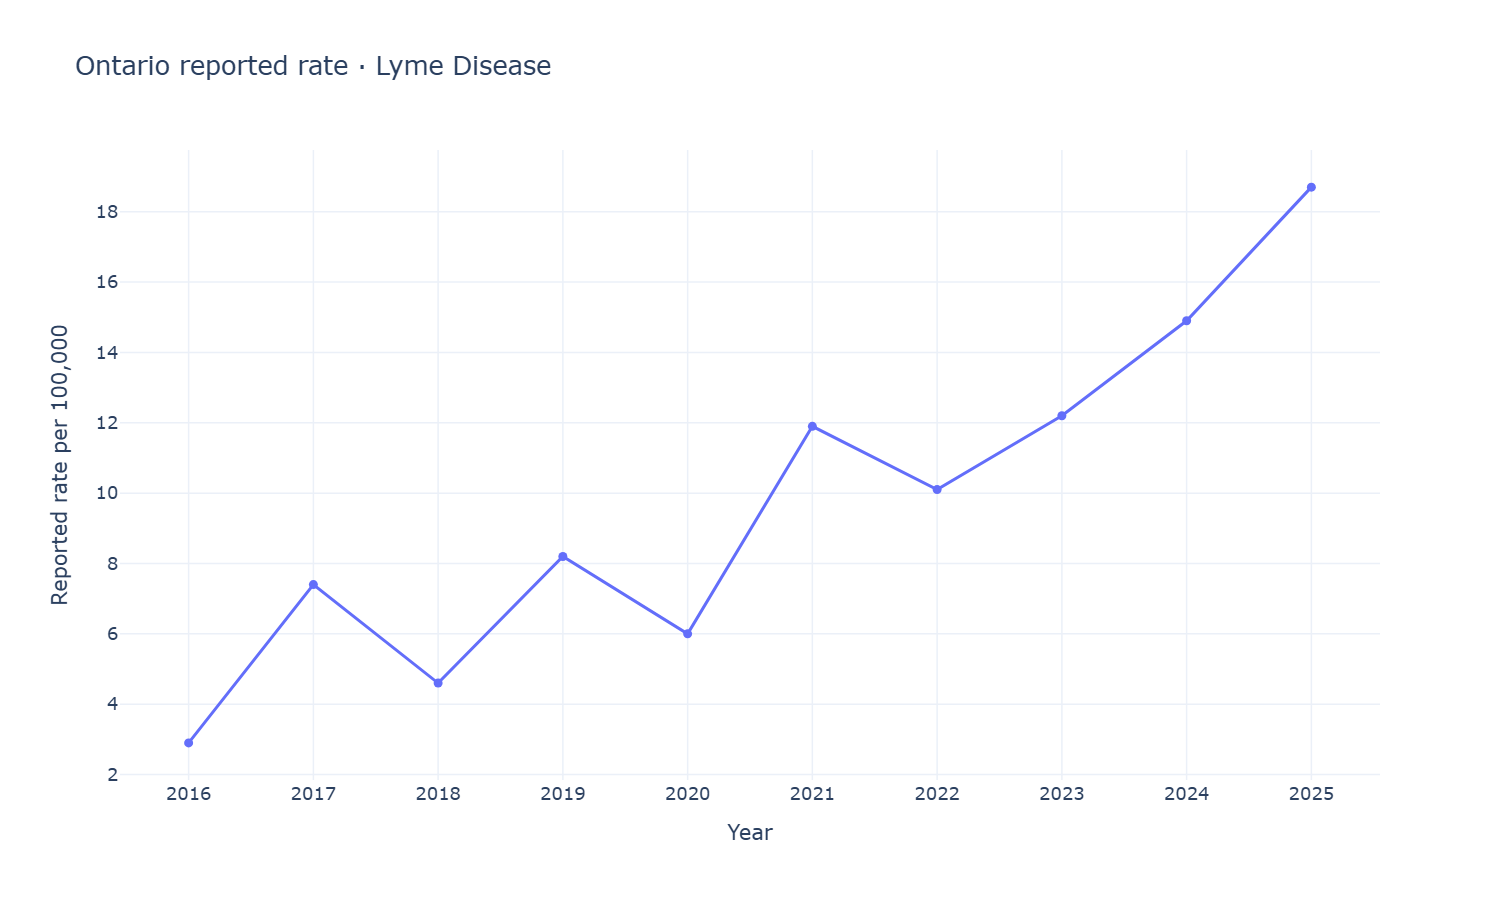

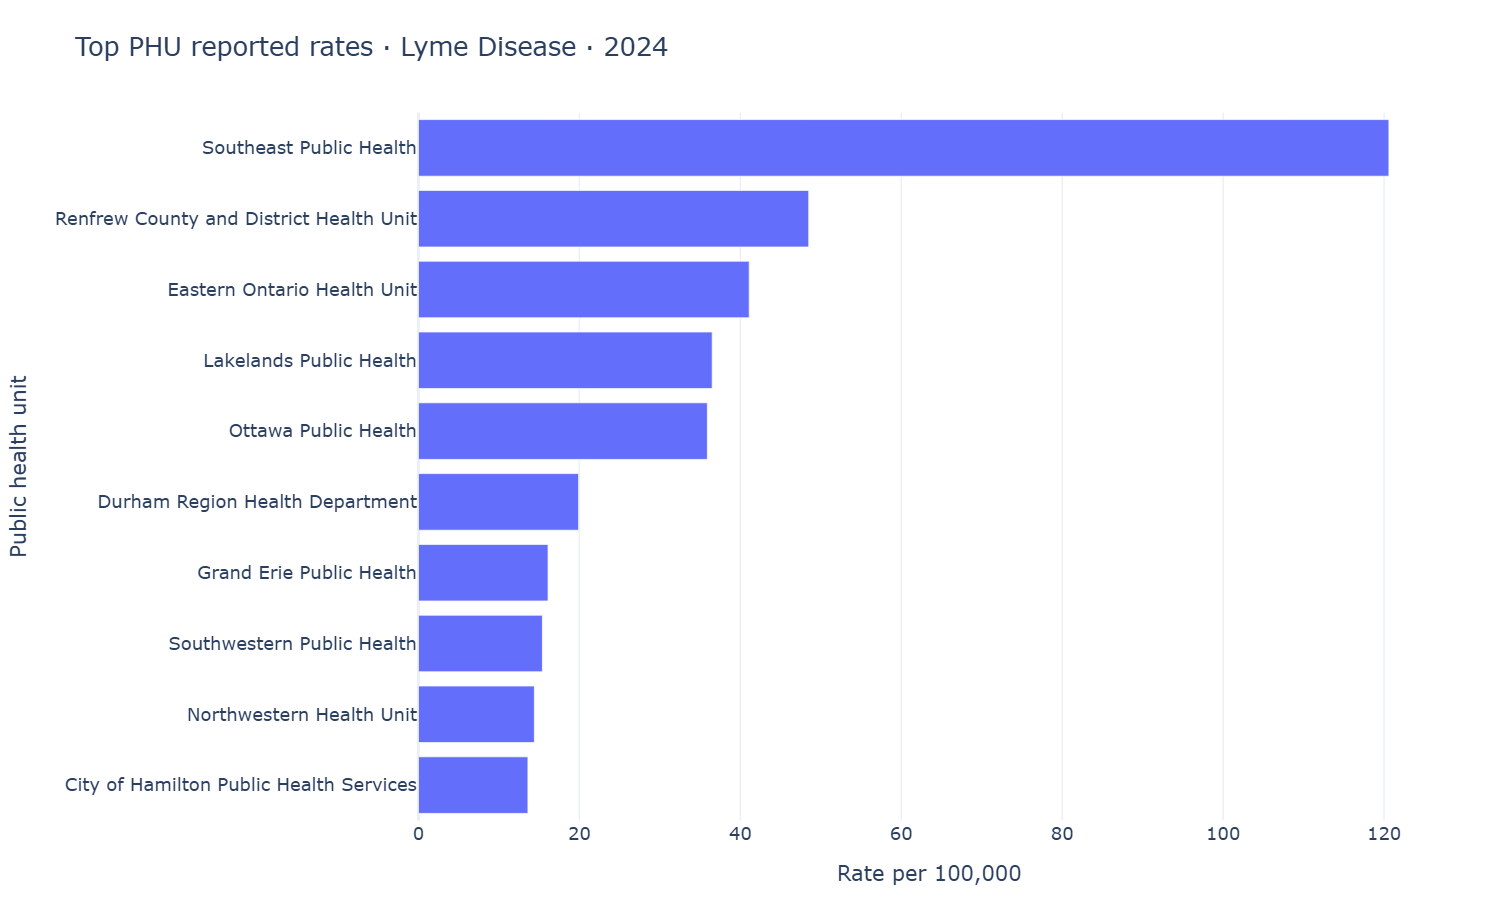

In [11]:
# ============================================================
# 09 | Dashboard Chart Previews
# ============================================================
preview = ontario_trends.loc[ontario_trends["Disease"].eq(PREVIEW_DISEASE)]
if preview.empty:
    raise ValueError(f"Unknown PREVIEW_DISEASE: {PREVIEW_DISEASE}")
fig = px.line(preview, x="Year", y="Rate per 100,000", markers=True,
              title=f"Ontario reported rate · {PREVIEW_DISEASE}",
              labels={"Rate per 100,000": "Reported rate per 100,000"})
fig.update_xaxes(dtick=1)
fig.update_layout(template="plotly_white", height=430)
fig.show()

local = phu_rates.loc[phu_rates["Disease"].eq(PREVIEW_DISEASE)
                      & phu_rates["Year"].eq(REFERENCE_YEAR)
                      & phu_rates["Rate_available"]]
local = local.nlargest(10, "Rate per 100,000").sort_values("Rate per 100,000")
if not local.empty:
    fig = px.bar(local, x="Rate per 100,000", y="Public health unit", orientation="h",
                 title=f"Top PHU reported rates · {PREVIEW_DISEASE} · {REFERENCE_YEAR}")
    fig.update_layout(template="plotly_white", height=460,
                      margin=dict(l=250, r=40, t=75, b=50))
    fig.show()
else:
    print("No comparable PHU rates for the selected disease and year.")

### 10 | Export Four Dashboard-Ready Tables & Filter Metadata

Created files:

| Filename | Dataset grain | Primary use |
|---|---|---|
| `dashboard_ontario_trends.csv` | Disease × year | Province trends, ranking |
| `dashboard_phu_rates.csv` | PHU × disease × year | Local rate comparisons |
| `dashboard_demographics.csv` | Disease × year × sex × age | Demographic distributions |
| `dashboard_outcomes.csv` | Disease × year × outcome | Hospitalization / deaths |
| `dashboard_diseases.csv` | Disease | Filter choices |

**Publish responsibly:** Check PHO attribution and redistribution requirements before adding any downloaded or derived CSV files to a *public* GitHub repository or Tableau Public.

In [12]:
# ============================================================
# 10 | Write Reusable Dashboard Files
# ============================================================
exports = {
    "dashboard_ontario_trends.csv": ontario_trends,
    "dashboard_phu_rates.csv": phu_rates,
    "dashboard_demographics.csv": demographics,
    "dashboard_outcomes.csv": reported_outcomes,
    "dashboard_diseases.csv": pd.DataFrame({
        "Disease": sorted(ontario_trends["Disease"].dropna().unique())
    }),
}
if EXPORT_TABLES:
    DASHBOARD_DIR.mkdir(parents=True, exist_ok=True)
    for filename, frame in exports.items():
        frame.to_csv(DASHBOARD_DIR / filename, index=False)
    print("Saved dashboard files to:", DASHBOARD_DIR)
else:
    print("Exports prepared in memory; EXPORT_TABLES is False.")

display(pd.DataFrame([{"File": filename, "Rows": len(frame), "Columns": len(frame.columns)}
                      for filename, frame in exports.items()]))

Saved dashboard files to: c:\Users\Honar\Downloads\PHO Project\outputs\dashboard


,File,Rows,Columns
0,dashboard_ontario_trends.csv,630,6
1,dashboard_phu_rates.csv,18734,7
2,dashboard_demographics.csv,7860,6
3,dashboard_outcomes.csv,648,6
4,dashboard_diseases.csv,67,1


### 11 | Verify Exports and Document Dashboard Boundaries

Verify file readability and exact row counts. An export being valid does **not** confirm clinical or epidemiological comparability; those limitations remain explicit.

In [13]:
# ============================================================
# 11 | Export Verification & Handoff Summary
# ============================================================
if EXPORT_TABLES:
    for filename, frame in exports.items():
        saved = pd.read_csv(DASHBOARD_DIR / filename)
        if len(saved) != len(frame) or list(saved.columns) != list(frame.columns):
            raise AssertionError(f"Export verification failed: {filename}")
    print("All five exported files verified (row counts and column names).")

print("Reporting years:", sorted(ontario_trends["Year"].unique().tolist()))
print("Default year:", REFERENCE_YEAR)
print("Ontario diseases:", ontario_trends["Disease"].nunique())
print("Outcome diseases:", reported_outcomes["Disease"].nunique())
print("Next: build the Streamlit application and separate Tableau Public dashboard.")

All five exported files verified (row counts and column names).
Reporting years: [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
Default year: 2024
Ontario diseases: 67
Outcome diseases: 38
Next: build the Streamlit application and separate Tableau Public dashboard.


### 12 | Interpretation, Dashboard Design & Publication Checklist

**Streamlit dashboard:** filters for disease and reporting year; province-wide case trends; local PHU rate ranking; disease-specific age/sex distributions; available outcome percentages. Always show units and the dataset's reporting geography.

**Tableau Public dashboard:** use the same four validated CSV exports as *separate logical tables or sources*. Avoid unconstrained many-to-many joins. Prefer separate sheets and filters over raw-grain table joins.

**Data caveats:**
- Population denominators can be absent; missing rates must remain missing.
- PHU administrative boundaries or labels may change during the period.
- Ontario, Canada, and constituent PHUs are **not** additive reporting levels.
- Age groups vary between diseases; age-band widths are unequal. Sex and age case charts are **not** risk comparisons.
- Outcome coverage is limited to the export's available diseases and years.
- Check 2025 data completeness and retrospective revisions before presenting 2025 as final.
- The count reconciliation exceptions found in Notebook 01 remain unresolved; no automatic corrections are made.
- Do not publish derived PHO datasets without verifying the source's reuse and attribution conditions.

**Important:** This notebook prepares and validates the *data layer*. A fully functional Streamlit web app and Tableau workbook are separate deliverables; a Plotly preview here is not a deployed dashboard.